# Gradiente Descendente (paso a paso)

**Programa Especializado en IA · C-DAC Noida · ITEC · India 2026**

*Resuelto paso a paso — PhD (c) Luis Correa*

---
En vez de dejar que scikit-learn calcule m y b, aquí los **encontramos nosotros mismos** con el algoritmo de gradiente descendente: el corazón de cómo *aprenden* los modelos.

## 1. ¿Qué es el gradiente descendente?

Queremos encontrar la recta $y = m\cdot x + b$ que mejor ajusta los datos. Para medir qué tan mala es una recta usamos el **costo** (error cuadrático medio, MSE):

$$\text{costo} = \frac{1}{n}\sum (y - y_{pred})^2$$

El gradiente descendente **ajusta m y b poco a poco**, en la dirección que reduce el costo, repitiendo muchas veces (iteraciones). El `learning_rate` controla el tamaño de cada paso.

In [1]:
import numpy as np

Esta es la función del curso. En cada iteración:
1. Calcula la predicción `y_predicted`.
2. Calcula el **costo** (qué tan lejos estamos).
3. Calcula las **derivadas** (pendientes) `md` y `bd`.
4. Da un paso: ajusta `m_curr` y `b_curr`.

La modificamos un poco para **guardar** el historial del costo y poder graficarlo.

In [2]:
def gradient_descent(x, y):
    m_curr = b_curr = 0
    iterations = 1000
    n = len(x)
    learning_rate = 0.08

    cost_history = []
    for i in range(iterations):
        y_predicted = m_curr * x + b_curr
        cost = (1/n) * sum([val**2 for val in (y - y_predicted)])
        md = -(2/n) * sum(x * (y - y_predicted))
        bd = -(2/n) * sum(y - y_predicted)
        m_curr = m_curr - learning_rate * md
        b_curr = b_curr - learning_rate * bd
        cost_history.append(cost)
        if i < 10 or i % 100 == 0:
            print("m {:.4f}, b {:.4f}, cost {:.6f}, iteración {}".format(m_curr, b_curr, cost, i))
    return m_curr, b_curr, cost_history

Usamos los mismos datos del curso (un caso donde sabemos que la respuesta es m=2, b=3).

In [3]:
x = np.array([1, 2, 3, 4, 5])     # área
y = np.array([5, 7, 9, 11, 13])   # precio

m, b, cost_history = gradient_descent(x, y)
print()
print(f"Resultado final -> m = {m:.4f}, b = {b:.4f}")

m 4.9600, b 1.4400, cost 89.000000, iteración 0
m 0.4992, b 0.2688, cost 71.105600, iteración 1
m 4.4516, b 1.4262, cost 56.829770, iteración 2
m 0.8922, b 0.5012, cost 45.439657, iteración 3
m 4.0413, b 1.4328, cost 36.350887, iteración 4
m 1.2009, b 0.7037, cost 29.097483, iteración 5
m 3.7096, b 1.4547, cost 23.307873, iteración 6
m 1.4425, b 0.8813, cost 18.685759, iteración 7
m 3.4407, b 1.4879, cost 14.994868, iteración 8
m 1.6309, b 1.0383, cost 12.046787, iteración 9
m 2.0395, b 2.8576, cost 0.003901, iteración 100
m 2.0025, b 2.9908, cost 0.000016, iteración 200
m 2.0002, b 2.9994, cost 0.000000, iteración 300
m 2.0000, b 3.0000, cost 0.000000, iteración 400
m 2.0000, b 3.0000, cost 0.000000, iteración 500
m 2.0000, b 3.0000, cost 0.000000, iteración 600
m 2.0000, b 3.0000, cost 0.000000, iteración 700
m 2.0000, b 3.0000, cost 0.000000, iteración 800
m 2.0000, b 3.0000, cost 0.000000, iteración 900

Resultado final -> m = 2.0000, b = 3.0000


## 2. ¿Cómo baja el costo?

Graficamos el **costo vs. iteraciones**. Debe bajar rápido y luego estabilizarse cerca de cero: eso significa que el algoritmo *convergió*.

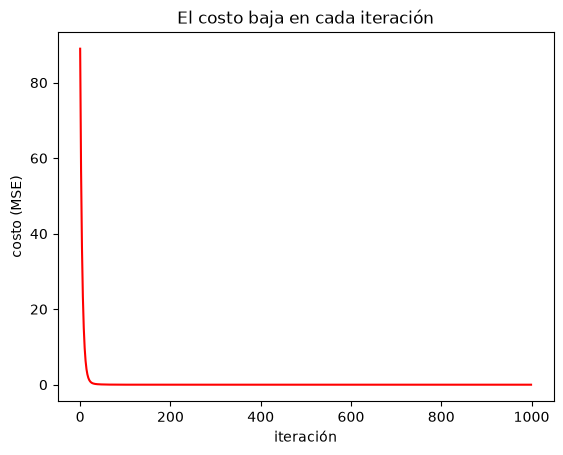

In [4]:
import matplotlib.pyplot as plt
plt.plot(range(len(cost_history)), cost_history, color='red')
plt.xlabel('iteración')
plt.ylabel('costo (MSE)')
plt.title('El costo baja en cada iteración')
plt.show()

También vemos la recta final encontrada a mano sobre los puntos.

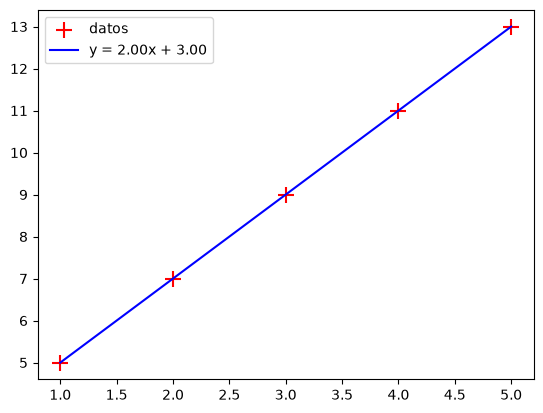

In [5]:
plt.scatter(x, y, color='red', marker='+', s=120, label='datos')
plt.plot(x, m*x + b, color='blue', label=f'y = {m:.2f}x + {b:.2f}')
plt.legend()
plt.show()

## Ejercicio práctico

**Enunciado:** Aplicar el gradiente descendente a los datos de `test_scores.csv` (puntajes de **matemáticas → ciencias de la computación**) y **comparar** el resultado (m y b) con el que entrega scikit-learn. Deben coincidir.

**Paso 1.** Cargamos los datos.

In [6]:
import pandas as pd
df_ts = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/test_scores.csv')
df_ts

,math,cs
0,92,98
1,56,68
2,88,81
3,70,80
4,80,83
5,49,52
6,65,66
7,35,30
8,66,68
9,67,73


**Paso 2.** Aplicamos nuestro gradiente descendente. Como los números son más grandes, usamos un `learning_rate` más pequeño y más iteraciones para que converja bien.

In [7]:
def gradient_descent_ts(x, y, iterations=1_000_000, learning_rate=0.0002):
    m_curr = b_curr = 0
    n = len(x)
    cost_history = []
    for i in range(iterations):
        y_predicted = m_curr * x + b_curr
        cost = (1/n) * sum((y - y_predicted) ** 2)
        md = -(2/n) * sum(x * (y - y_predicted))
        bd = -(2/n) * sum(y - y_predicted)
        m_curr = m_curr - learning_rate * md
        b_curr = b_curr - learning_rate * bd
        cost_history.append(cost)
    return m_curr, b_curr, cost_history

x_ts = np.array(df_ts.math)
y_ts = np.array(df_ts.cs)
m_ts, b_ts, hist_ts = gradient_descent_ts(x_ts, y_ts)
print(f"Gradiente descendente -> m = {m_ts:.4f}, b = {b_ts:.4f}")

Gradiente descendente -> m = 1.0177, b = 1.9152


**Paso 3.** Comparamos con scikit-learn (la respuesta 'oficial').

In [8]:
from sklearn.linear_model import LinearRegression
reg_ts = LinearRegression()
reg_ts.fit(df_ts[['math']], df_ts.cs)
print(f"scikit-learn          -> m = {reg_ts.coef_[0]:.4f}, b = {reg_ts.intercept_:.4f}")

scikit-learn          -> m = 1.0177, b = 1.9152


**Paso 4.** Dibujamos ambas rectas (deben quedar prácticamente encima una de otra).

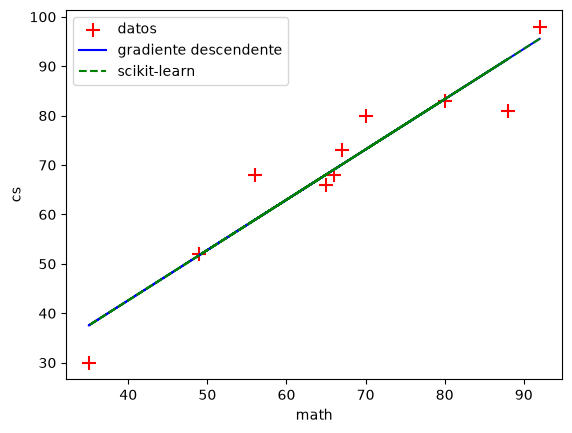

In [9]:
plt.scatter(x_ts, y_ts, color='red', marker='+', s=100, label='datos')
plt.plot(x_ts, m_ts*x_ts + b_ts, color='blue', label='gradiente descendente')
plt.plot(x_ts, reg_ts.predict(df_ts[['math']]), color='green', linestyle='--', label='scikit-learn')
plt.xlabel('math'); plt.ylabel('cs'); plt.legend()
plt.show()

**Conclusión:** nuestro algoritmo hecho a mano llega **al mismo m y b** que scikit-learn. Esto demuestra que el gradiente descendente es realmente el motor que está detrás del ajuste de un modelo lineal.